Iteration: 1 Best Fitness: 0.10894
Iteration: 2 Best Fitness: 0.01105
Iteration: 3 Best Fitness: 0.01105
Iteration: 4 Best Fitness: 0.01105
Iteration: 5 Best Fitness: 0.01105
Iteration: 6 Best Fitness: 0.01105
Iteration: 7 Best Fitness: 0.01105
Iteration: 8 Best Fitness: 0.01105
Iteration: 9 Best Fitness: 0.00381
Iteration: 10 Best Fitness: 0.00381
Iteration: 11 Best Fitness: 0.00381
Iteration: 12 Best Fitness: 0.00381
Iteration: 13 Best Fitness: 0.00381
Iteration: 14 Best Fitness: 0.00375
Iteration: 15 Best Fitness: 0.00375
Iteration: 16 Best Fitness: 0.00375
Iteration: 17 Best Fitness: 0.00375
Iteration: 18 Best Fitness: 0.00375
Iteration: 19 Best Fitness: 0.00267
Iteration: 20 Best Fitness: 0.00267
Iteration: 21 Best Fitness: 0.00267
Iteration: 22 Best Fitness: 0.00267
Iteration: 23 Best Fitness: 0.00267
Iteration: 24 Best Fitness: 0.00246
Iteration: 25 Best Fitness: 0.00246
Iteration: 26 Best Fitness: 0.00224
Iteration: 27 Best Fitness: 0.00224
Iteration: 28 Best Fitness: 0.00169
I

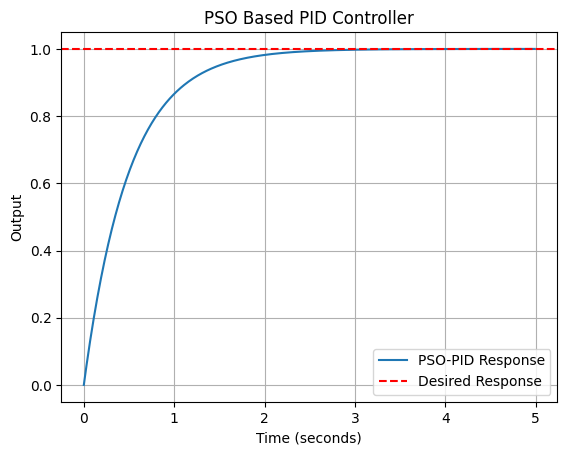

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# PSO Parameters
N = 80
iterations = 100
w_max = 0.9
w_min = 0.4
c1 = 2
c2 = 2

# PID parameter limits
lower = np.array([0, 0, 0])
upper = np.array([200, 100, 50])

# Plant parameters (example second-order system)
dt = 0.01
T = 5
time = np.arange(0, T, dt)

def simulate_pid(Kp, Ki, Kd):
    y = np.zeros(len(time))
    error_sum = 0
    previous_error = 0

    for i in range(1, len(time)):
        error = 1 - y[i-1]

        error_sum += error * dt
        derivative = (error - previous_error) / dt

        u = Kp*error + Ki*error_sum + Kd*derivative

        # Example plant dynamics
        acceleration = u - 2*y[i-1] - 0.5*(y[i-1]-y[i-2] if i > 1 else 0)/dt

        y[i] = y[i-1] + acceleration*dt*dt
        previous_error = error

    return y

# Fitness function
def fitness(position):
    Kp, Ki, Kd = position

    y = simulate_pid(Kp, Ki, Kd)

    if np.any(np.isnan(y)) or np.max(np.abs(y)) > 100:
        return 1e10

    overshoot = max(0, (np.max(y)-1)*100)
    error = abs(1-y[-1])

    # Minimize error and overshoot
    return overshoot + 100*error

# Initialize particles
positions = np.random.uniform(lower, upper, (N, 3))
velocities = np.zeros((N, 3))

pbest = positions.copy()
pbest_fitness = np.array([fitness(p) for p in positions])

gbest_index = np.argmin(pbest_fitness)
gbest = pbest[gbest_index].copy()

# PSO Algorithm
for iteration in range(iterations):

    w = w_max - ((w_max-w_min)*iteration/iterations)

    for i in range(N):

        r1 = np.random.rand(3)
        r2 = np.random.rand(3)

        velocities[i] = (
            w*velocities[i]
            + c1*r1*(pbest[i]-positions[i])
            + c2*r2*(gbest-positions[i])
        )

        positions[i] += velocities[i]
        positions[i] = np.clip(positions[i], lower, upper)

        current_fitness = fitness(positions[i])

        if current_fitness < pbest_fitness[i]:
            pbest[i] = positions[i].copy()
            pbest_fitness[i] = current_fitness

    gbest_index = np.argmin(pbest_fitness)
    gbest = pbest[gbest_index].copy()

    print("Iteration:", iteration+1,
          "Best Fitness:", round(pbest_fitness[gbest_index], 5))

# Display optimal PID values
Kp, Ki, Kd = gbest

print("\nOptimal PID Parameters")
print("Kp =", Kp)
print("Ki =", Ki)
print("Kd =", Kd)

# Plot response
response = simulate_pid(Kp, Ki, Kd)

plt.plot(time, response, label="PSO-PID Response")
plt.axhline(1, color='red', linestyle='--', label="Desired Response")

plt.xlabel("Time (seconds)")
plt.ylabel("Output")
plt.title("PSO Based PID Controller")
plt.legend()
plt.grid()
plt.show()
